# Grafos mecánicos

## Representación, ciclos y dinámica de mecanismos planares

**Luis Alejandro Rodríguez Arenas**  
Código 202321287  
MATE-1018 · Proyecto final

El cuaderno desarrolla una ruta desde la representación de un mecanismo mediante un grafo hasta el uso de sus ciclos en cinemática y dinámica. Primero se construye un cuatro barras y se estudian su matriz de adyacencia, la permutación de etiquetas y los cambios de conectividad. Después se obtiene una base de ciclos fundamentales y se traduce cada ciclo en un cierre vectorial. El quinteto E de Norton muestra cómo una misma conectividad puede corresponder a comportamientos distintos al cambiar la geometría. Por último, el submecanismo planar del EEZYbotARM permite aplicar el procedimiento a cierres, velocidades, aceleraciones y balances de Newton y Euler.

### Cómo recorrer el cuaderno

Ejecute las celdas en orden desde la carpeta del proyecto. Las dependencias están en requirements.txt. Las animaciones se guardan en animaciones/ y también quedan incrustadas en este archivo. index.html contiene una versión estática para consultar desde GitHub Pages sin instalar Python.

## 1. Modelo matemático de un grafo mecánico

Un grafo simple no dirigido registra incidencias entre vértices. Para representar un mecanismo planar se interpreta cada vértice como un eslabón rígido y cada arista como una articulación revoluta que une dos eslabones. Se distingue el bastidor mediante un vértice designado y se completa la descripción con información geométrica e inercial:

$$
G_M=(V,E,g,\lambda_V,\lambda_E,\rho,\mu).
$$

Aquí $g\in V$ identifica el bastidor. Las etiquetas $\lambda_V$ describen propiedades de los eslabones, por ejemplo si son binarios o ternarios; $\lambda_E$ registra el tipo de articulación; $\rho(v,e)$ da la posición local del pivote de la articulación $e$ sobre el eslabón $v$; y $\mu(v)$ contiene su masa y momento de inercia.

La matriz de adyacencia describe solo la conectividad. La pose fija del bastidor, las posiciones locales de los pivotes y las propiedades inerciales aportan los datos necesarios para formular las ecuaciones mecánicas. Que el mecanismo sea planar significa que sus movimientos ocurren en un plano, no que su grafo deba admitir un dibujo sin cruces.

La exposición considera articulaciones revolutas binarias y un grafo simple. Si un mismo par de eslabones estuviera unido por más de una articulación, cada unión tendría que conservar su identidad y se usaría un multigrafo.

## 2. Matriz de adyacencia, orden y operaciones

Considérese un mecanismo de cuatro barras. Sus cuatro vértices se denotan $u_1,u_2,u_3,u_4$, donde $u_1$ es el bastidor, $u_2$ la manivela, $u_3$ el acoplador y $u_4$ el balancín. Las articulaciones dan las aristas $\{u_1,u_2\}$, $\{u_2,u_3\}$, $\{u_3,u_4\}$ y $\{u_4,u_1\}$.

En el orden $u_1,u_2,u_3,u_4$, la matriz de adyacencia sigue la convención del curso:

$$
\operatorname{Adj}[i,j]=
\begin{cases}
1,&\text{si }u_i\sim u_j,\\
0,&\text{en otro caso.}
\end{cases}
$$

El siguiente diagrama separa el mecanismo físico de su grafo. En el grafo los vértices son eslabones y las aristas son articulaciones.

In [1]:
import sys
import base64
from pathlib import Path
PROJECT = Path.cwd().resolve()
while not (PROJECT / "demo" / "model.py").exists() and PROJECT.parent != PROJECT:
    PROJECT = PROJECT.parent
if not (PROJECT / "demo" / "model.py").exists():
    raise FileNotFoundError("Abra el cuaderno desde grafos_mecanicos_final o una subcarpeta.")
sys.path.insert(0, str(PROJECT / "demo"))

import model as mech
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import display, Markdown, HTML, Image

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.titlesize": 11})
print("Carpeta del proyecto:", PROJECT)
print("Modelo importado desde:", Path(mech.__file__).resolve())

Carpeta del proyecto: C:\Users\aleja\LuigiToby\library\academy\202620\MATE1018\proyecto\grafos_mecanicos_final
Modelo importado desde: C:\Users\aleja\LuigiToby\library\academy\202620\MATE1018\proyecto\grafos_mecanicos_final\demo\model.py


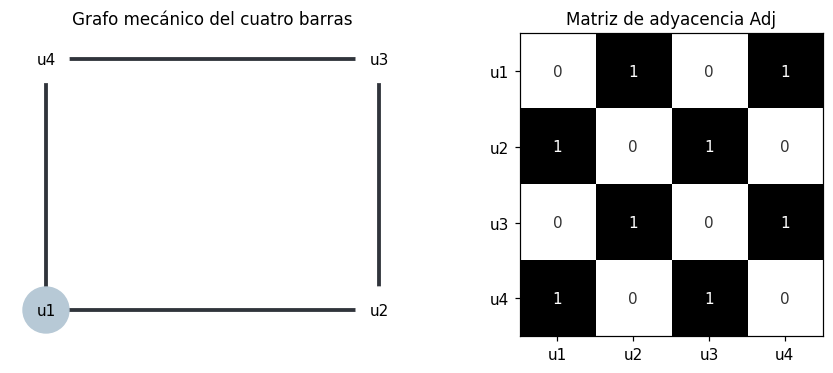

,u1,u2,u3,u4
u1,0,1,0,1
u2,1,0,1,0
u3,0,1,0,1
u4,1,0,1,0


In [2]:
vertices_4 = ["u1", "u2", "u3", "u4"]
edges_4 = [("u1", "u2"), ("u2", "u3"), ("u3", "u4"), ("u4", "u1")]
G4 = nx.Graph()
G4.add_nodes_from(vertices_4)
G4.add_edges_from(edges_4)
Adj4 = nx.to_numpy_array(G4, nodelist=vertices_4, dtype=int)
pos4 = {"u1": (0, 0), "u2": (1, 0), "u3": (1, 1), "u4": (0, 1)}
node_colors = ["#b7c9d6" if v == "u1" else "white" for v in vertices_4]
fig, ax = plt.subplots(1, 2, figsize=(8.5, 3.5), gridspec_kw={"width_ratios": [1, 1.2]})
nx.draw_networkx(G4, pos4, ax=ax[0], node_color=node_colors, edge_color="#30343b",
                 node_size=900, width=2.5, font_size=10)
ax[0].set_title("Grafo mecánico del cuatro barras")
ax[0].axis("off")
ax[1].imshow(Adj4, cmap="Greys", vmin=0, vmax=1)
ax[1].set_xticks(range(4), vertices_4)
ax[1].set_yticks(range(4), vertices_4)
ax[1].set_title("Matriz de adyacencia Adj")
for i in range(4):
    for j in range(4):
        ax[1].text(j, i, str(Adj4[i, j]), ha="center", va="center",
                   color="white" if Adj4[i, j] else "#333")
fig.tight_layout()
plt.show()
display(pd.DataFrame(Adj4, index=vertices_4, columns=vertices_4))

### Movimiento del cuatro barras

La animación muestra una configuración física compatible con la conectividad del grafo. El bastidor u1 permanece fijo, mientras que u2, u3 y u4 giran en sus articulaciones. Este ejemplo permite distinguir un cambio de etiquetas de un cambio real de conexiones.

Animación guardada: animaciones\cuatro_barras.gif



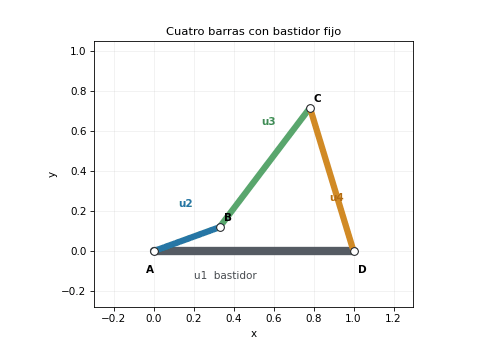

In [3]:
def puntos_cuatro_barras(theta):
    A = np.array([0.0, 0.0])
    D = np.array([1.0, 0.0])
    r_manivela, r_acoplador, r_balancin = 0.35, 0.75, 0.75
    B = A + r_manivela * np.array([np.cos(theta), np.sin(theta)])
    delta = D - B
    distancia = np.linalg.norm(delta)
    eje = delta / distancia
    perpendicular = np.array([-eje[1], eje[0]])
    a = (r_acoplador**2 - r_balancin**2 + distancia**2) / (2 * distancia)
    h = np.sqrt(max(0.0, r_acoplador**2 - a**2))
    candidatos = (B + a * eje + h * perpendicular, B + a * eje - h * perpendicular)
    C = max(candidatos, key=lambda punto: punto[1])
    return A, B, C, D

angulos_4 = np.linspace(np.deg2rad(20), np.deg2rad(145), 52)
fig, ax = plt.subplots(figsize=(6.6, 4.6))

def actualizar_cuatro_barras(i):
    ax.clear()
    A, B, C, D = puntos_cuatro_barras(angulos_4[i])
    ax.plot([A[0], D[0]], [A[1], D[1]], color="#555b63", lw=8, solid_capstyle="round")
    ax.plot([A[0], B[0]], [A[1], B[1]], color="#2676a5", lw=6, solid_capstyle="round")
    ax.plot([B[0], C[0]], [B[1], C[1]], color="#59a66d", lw=6, solid_capstyle="round")
    ax.plot([C[0], D[0]], [C[1], D[1]], color="#d18a25", lw=6, solid_capstyle="round")
    ax.scatter([A[0], B[0], C[0], D[0]], [A[1], B[1], C[1], D[1]],
               s=55, c="white", edgecolors="#20252a", zorder=5)
    for name, point, offset in (("A", A, (-.04, -.11)), ("B", B, (.02, .03)),
                                ("C", C, (.02, .03)), ("D", D, (.02, -.11))):
        ax.text(point[0] + offset[0], point[1] + offset[1], name, fontsize=10, weight="bold")
    ax.text(.36, -.14, "u1  bastidor", color="#454a50", ha="center")
    ax.text(.12, .22, "u2", color="#2676a5", weight="bold")
    ax.text(.54, .63, "u3", color="#438856", weight="bold")
    ax.text(.88, .25, "u4", color="#b36c13", weight="bold")
    ax.set_xlim(-.30, 1.30)
    ax.set_ylim(-.28, 1.05)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title("Cuatro barras con bastidor fijo")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.grid(alpha=.18)

anim_4 = FuncAnimation(fig, actualizar_cuatro_barras, frames=len(angulos_4),
                       interval=90, blit=False, cache_frame_data=False)
gif_4 = PROJECT / "animaciones" / "cuatro_barras.gif"
gif_4.parent.mkdir(exist_ok=True)
anim_4.save(gif_4, writer=PillowWriter(fps=12), dpi=75)
plt.close(fig)
gif_data = base64.b64encode(gif_4.read_bytes()).decode("ascii")
display(HTML(f'<img alt="Animación del mecanismo de cuatro barras" src="data:image/gif;base64,{gif_data}" width="620">'))
print("Animación guardada:", gif_4.relative_to(PROJECT))

### Permutar la numeración de los eslabones

Reordenar o renombrar los vértices no cambia las articulaciones físicas. Si se usa el nuevo orden $u_1,u_3,u_2,u_4$, se permutan las mismas filas y columnas de la matriz:

$$
\operatorname{Adj}_{\mathrm{nuevo}}=P^{\mathsf T}\operatorname{Adj}P.
$$

La ilustración conserva los cuatro eslabones en su lugar y cambia únicamente las etiquetas $u_2$ y $u_3$. Esta operación representa el mismo grafo con otra numeración. Una modificación mecánica real, como mover una articulación a otro eslabón, cambia el conjunto de aristas y se ilustra en la sección siguiente.

Matriz del grafo renombrado = Pᵀ Adj P: True


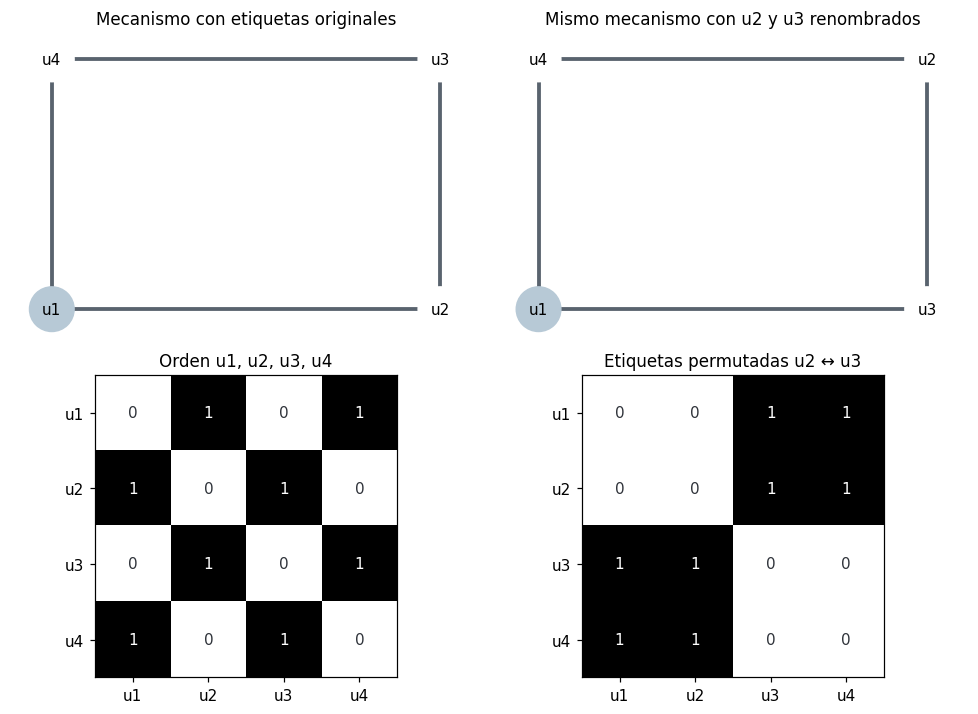

In [4]:
nuevo_orden = ["u1", "u3", "u2", "u4"]
indices = [vertices_4.index(v) for v in nuevo_orden]
P = np.eye(len(vertices_4), dtype=int)[:, indices]
Adj_perm = P.T @ Adj4 @ P
etiquetas_perm = {"u1": "u1", "u2": "u3", "u3": "u2", "u4": "u4"}
G_relabel = nx.relabel_nodes(G4, etiquetas_perm)
Adj_relabel = nx.to_numpy_array(G_relabel, nodelist=vertices_4, dtype=int)
G_relabel = nx.relabel_nodes(G4, etiquetas_perm)
Adj_relabel = nx.to_numpy_array(G_relabel, nodelist=vertices_4, dtype=int)
fig, ax = plt.subplots(2, 2, figsize=(9, 6.6))
nx.draw_networkx_edges(G4, pos4, ax=ax[0, 0], edge_color="#59636e", width=2.5)
nx.draw_networkx_nodes(G4, pos4, ax=ax[0, 0], node_color=node_colors, node_size=850)
nx.draw_networkx_labels(G4, pos4, ax=ax[0, 0], font_size=10)
ax[0, 0].set_title("Mecanismo con etiquetas originales")
nx.draw_networkx_edges(G4, pos4, ax=ax[0, 1], edge_color="#59636e", width=2.5)
nx.draw_networkx_nodes(G4, pos4, ax=ax[0, 1], node_color=node_colors, node_size=850)
nx.draw_networkx_labels(G4, pos4, labels=etiquetas_perm, ax=ax[0, 1], font_size=10)
ax[0, 1].set_title("Mismo mecanismo con u2 y u3 renombrados")
for axis in ax[0]:
    axis.axis("off")
for axis, matrix, labels, title in (
    (ax[1, 0], Adj4, vertices_4, "Orden u1, u2, u3, u4"),
    (ax[1, 1], Adj_relabel, vertices_4, "Etiquetas permutadas u2 ↔ u3"),
):
    axis.imshow(matrix, cmap="Greys", vmin=0, vmax=1)
    axis.set_xticks(range(4), labels)
    axis.set_yticks(range(4), labels)
    axis.set_title(title)
    for i in range(4):
        for j in range(4):
            axis.text(j, i, str(matrix[i, j]), ha="center", va="center",
                       color="white" if matrix[i, j] else "#30343b")
fig.tight_layout()
plt.show()
print("Matriz del grafo renombrado = Pᵀ Adj P:",
      np.array_equal(Adj_relabel, Adj_perm))

### Quitar un eslabón, quitar una unión y cambiar una unión

Eliminar un eslabón equivale a retirar su vértice y todas las aristas incidentes; en la matriz de adyacencia se eliminan la fila y la columna correspondientes. Eliminar una articulación entre dos eslabones conserva los vértices, pero cambia a cero las dos entradas simétricas asociadas. Reubicar una articulación requiere quitar la arista anterior y añadir la nueva. Cada operación cambia la matriz y puede cambiar el número de componentes y ciclos.

Original
Se elimina u3
Se elimina la unión u2—u3
La unión u2—u3 pasa a u2—u4


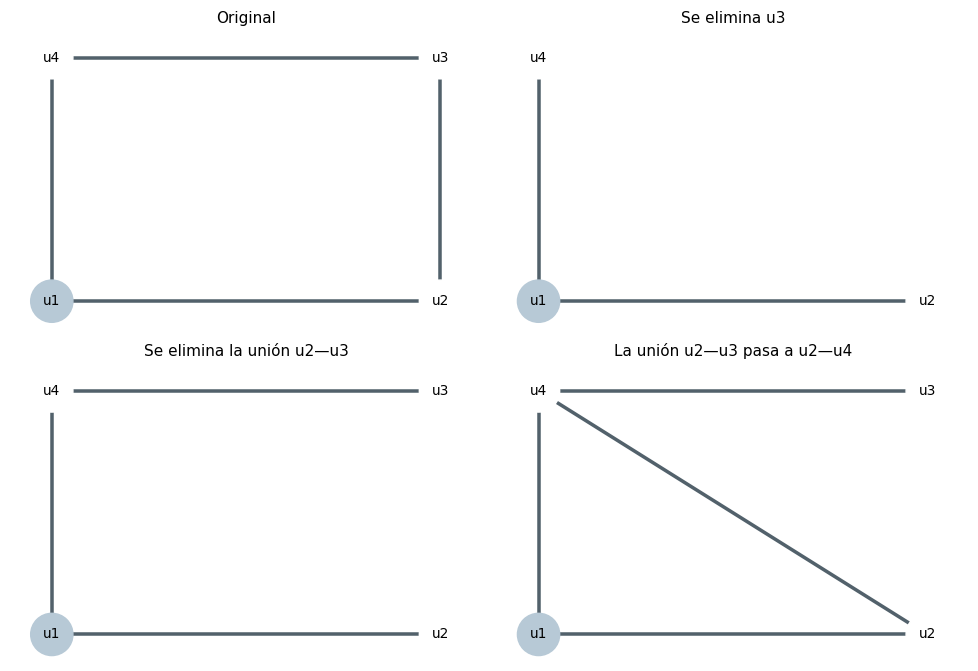

,u1,u2,u3,u4
u1,0,1,0,1
u2,1,0,1,0
u3,0,1,0,1
u4,1,0,1,0


,u1,u2,u4
u1,0,1,1
u2,1,0,0
u4,1,0,0


,u1,u2,u3,u4
u1,0,1,0,1
u2,1,0,0,0
u3,0,0,0,1
u4,1,0,1,0


,u1,u2,u3,u4
u1,0,1,0,1
u2,1,0,0,1
u3,0,0,0,1
u4,1,1,1,0


In [5]:
def grafo_desde_aristas(vertices, aristas):
    grafo = nx.Graph()
    grafo.add_nodes_from(vertices)
    grafo.add_edges_from(aristas)
    return grafo

G_sin_u3 = grafo_desde_aristas(["u1", "u2", "u4"], [("u1", "u2"), ("u4", "u1")])
G_sin_union = grafo_desde_aristas(vertices_4, [e for e in edges_4 if set(e) != {"u2", "u3"}])
aristas_cambiadas = [e for e in edges_4 if set(e) != {"u2", "u3"}] + [("u2", "u4")]
G_union_movida = grafo_desde_aristas(vertices_4, aristas_cambiadas)
casos_grafo = [
    ("Original", G4),
    ("Se elimina u3", G_sin_u3),
    ("Se elimina la unión u2—u3", G_sin_union),
    ("La unión u2—u3 pasa a u2—u4", G_union_movida),
]
fig, ax = plt.subplots(2, 2, figsize=(9, 6.2))
for axis, (titulo, grafo) in zip(ax.flat, casos_grafo):
    pos_local = {v: pos4[v] for v in grafo.nodes}
    colores = ["#b7c9d6" if v == "u1" else "white" for v in grafo.nodes]
    nx.draw_networkx(grafo, pos_local, ax=axis, node_color=colores, node_size=760,
                     edge_color="#52616b", width=2.3, font_size=9)
    axis.set_title(titulo, fontsize=10)
    axis.axis("off")
fig.tight_layout()
plt.show()
for titulo, grafo in casos_grafo:
    orden = list(grafo.nodes)
    matriz = nx.to_numpy_array(grafo, nodelist=orden, dtype=int)
    print(titulo)
    display(pd.DataFrame(matriz, index=orden, columns=orden))

## 3. Árbol recubridor y ciclos fundamentales

Para un grafo conexo, un árbol recubridor conserva todos sus $n$ vértices y contiene $n-1$ aristas. Si el grafo tiene $\epsilon$ aristas, las $\epsilon-n+1$ aristas que no están en el árbol son cuerdas. Al añadir una cuerda $xy$ al árbol aparece un único ciclo, porque el árbol contiene un único camino entre $x$ e $y$. Ese ciclo se llama ciclo fundamental de la cuerda respecto al árbol.

Los ciclos fundamentales forman una base del espacio de ciclos. Cada ciclo fundamental contiene su propia cuerda y no contiene las demás, por lo que son independientes. Para ver que generan todos los ciclos, considérese un ciclo cualquiera y súmense, módulo dos, los ciclos fundamentales asociados a sus cuerdas. Todas las cuerdas se cancelan y el residuo tendría que ser un ciclo formado solo por aristas del árbol. Un árbol no contiene ciclos, así que el residuo es vacío. Por tanto, el número de ciclos fundamentales es

$$
\operatorname{rango\ de\ ciclos}(G)=\epsilon-n+1.
$$

La matriz de incidencia orientada ofrece una verificación algebraica. Al orientar cada arista, su núcleo contiene ciclos con signos compatibles con esa orientación. Los signos pueden cambiar al reorientar las aristas, pero el conjunto de aristas de cada ciclo permanece.

Cuatro barras: n=4, ε=4
Rango de ciclos: ε−n+1 = 1
Aristas del árbol recubridor: [('u1', 'u2'), ('u1', 'u4'), ('u2', 'u3')]
Ciclos fundamentales: [['u3', 'u2', 'u1', 'u4', 'u3']]


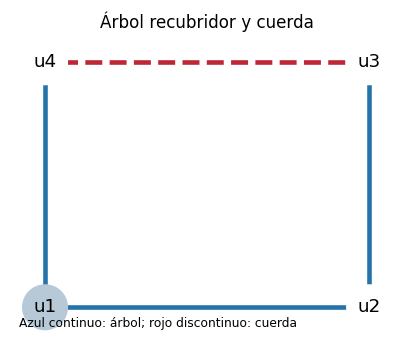

In [6]:
def ciclo_fundamental(G, raiz=None):
    if G.number_of_nodes() == 0:
        return nx.Graph(), []
    raiz = next(iter(G.nodes)) if raiz is None else raiz
    tree = nx.Graph()
    tree.add_nodes_from(G.nodes)
    tree.add_edges_from(nx.bfs_edges(G, raiz))
    tree_set = {frozenset(e) for e in tree.edges}
    chords = [e for e in G.edges if frozenset(e) not in tree_set]
    basis = []
    for u, v in chords:
        path = nx.shortest_path(tree, u, v)
        basis.append(path + [u])
    return tree, basis

tree4, basis4 = ciclo_fundamental(G4, "u1")
rango_4 = G4.number_of_edges() - G4.number_of_nodes() + 1
print(f"Cuatro barras: n={G4.number_of_nodes()}, ε={G4.number_of_edges()}")
print(f"Rango de ciclos: ε−n+1 = {rango_4}")
print("Aristas del árbol recubridor:", list(tree4.edges))
print("Ciclos fundamentales:", basis4)
fig, ax = plt.subplots(figsize=(4.6, 3.5))
nx.draw_networkx_nodes(G4, pos4, ax=ax, node_color=node_colors, node_size=850)
nx.draw_networkx_labels(G4, pos4, ax=ax)
nx.draw_networkx_edges(G4, pos4, edgelist=list(tree4.edges), ax=ax,
                       edge_color="#2574a9", width=3)
chords4 = [e for e in G4.edges if frozenset(e) not in {frozenset(x) for x in tree4.edges}]
nx.draw_networkx_edges(G4, pos4, edgelist=chords4, ax=ax,
                       edge_color="#bd2635", style="dashed", width=3)
ax.set_title("Árbol recubridor y cuerda")
ax.text(.02, .02, "Azul continuo: árbol; rojo discontinuo: cuerda",
        transform=ax.transAxes, fontsize=8)
ax.axis("off")
plt.show()

## 4. Ejemplo de Norton: una misma conectividad, dos movilidades

El quinteto E considerado por Norton [3] contiene cinco eslabones: el bastidor fijo $F$, un eslabón ternario móvil $P$ y tres eslabones binarios $L_1,L_2,L_3$. Cada barra binaria se articula con $F$ y con $P$. Por ello el grafo es $K_{2,3}$ y tiene seis articulaciones revolutas. El dibujo geométrico es esquemático y distingue los dos eslabones ternarios de las tres barras que los conectan.

El conteo de Grübler para mecanismos planares da

$$
M=3(L-1)-2J=3(5-1)-2(6)=0.
$$

Este conteo predice movilidad nula cuando las restricciones geométricas tienen rango máximo. Para examinar una configuración especial se escriben dos ciclos vectoriales independientes. Sean $\mathbf b_i$ las posiciones de los pivotes fijos sobre $F$, $\mathbf p_i$ las posiciones locales de los pivotes sobre $P$, $\mathbf x$ la traslación de $P$, $\theta$ su orientación y $\phi_i$ el ángulo de la barra $L_i$, cuya longitud es $\ell$. Se define $\mathbf u(\phi)=(\cos\phi,\sin\phi)^{\mathsf T}$ y $R(\theta)$ como la matriz de rotación plana. Al restar el cierre de la primera barra de los otros dos se elimina $\mathbf x$:

$$
\boldsymbol\Phi_{1i}(q)=R(\theta)(\mathbf p_i-\mathbf p_1)
-(\mathbf b_i-\mathbf b_1)-\ell\bigl[\mathbf u(\phi_i)-\mathbf u(\phi_1)\bigr]=\mathbf 0,
\qquad i=2,3,
$$

con $q=(\phi_1,\phi_2,\phi_3,\theta)$. Los dos cierres vectoriales forman cuatro ecuaciones escalares. En una configuración regular, la movilidad local de estas cuatro coordenadas es $4-\operatorname{rank}(D\boldsymbol\Phi)$.

In [7]:
def rotacion(theta):
    c, s = np.cos(theta), np.sin(theta)
    return np.array([[c, -s], [s, c]])

def u(theta):
    return np.array([np.cos(theta), np.sin(theta)])

def derivada_u(theta):
    return np.array([-np.sin(theta), np.cos(theta)])

def jacobiano_norton(p, ell, phi, theta):
    # Jacobiano de dos cierres vectoriales: columnas phi1, phi2, phi3, theta.
    J = np.zeros((4, 4))
    R = rotacion(theta)
    J90 = np.array([[0., -1.], [1., 0.]])
    for bloque, i in enumerate((1, 2)):
        filas = slice(2 * bloque, 2 * bloque + 2)
        J[filas, 0] = ell * derivada_u(phi[0])
        J[filas, i] = -ell * derivada_u(phi[i])
        J[filas, 3] = J90 @ R @ (p[i] - p[0])
    return J

ell = 0.060
p_general = np.array([[0.000, 0.000], [0.080, 0.000], [0.030, 0.065]])
phi_general = np.deg2rad([25.0, 95.0, 145.0])
theta_general = np.deg2rad(18.0)
R = rotacion(theta_general)
b_general = np.zeros_like(p_general)
for i in (1, 2):
    b_general[i] = R @ (p_general[i] - p_general[0]) - ell * (u(phi_general[i]) - u(phi_general[0]))
x_general = b_general[0] + ell * u(phi_general[0]) - R @ p_general[0]
J_general = jacobiano_norton(p_general, ell, phi_general, theta_general)

p_especial = np.array([[0.000, 0.000], [0.065, 0.000], [0.130, 0.000]])
b_especial = p_especial.copy()
phi_especial = np.full(3, np.pi / 2)
J_especial = jacobiano_norton(p_especial, ell, phi_especial, 0.0)
print("Rango genérico:", np.linalg.matrix_rank(J_general, tol=1e-10), "de 4")
print("Rango paralelo:", np.linalg.matrix_rank(J_especial, tol=1e-10), "de 4")
print("J especial · (1,1,1,0):", J_especial @ np.array([1., 1., 1., 0.]))
print("Dimensión del núcleo especial:", 4 - np.linalg.matrix_rank(J_especial, tol=1e-10))

Rango genérico: 4 de 4
Rango paralelo: 3 de 4
J especial · (1,1,1,0): [0. 0. 0. 0.]
Dimensión del núcleo especial: 1


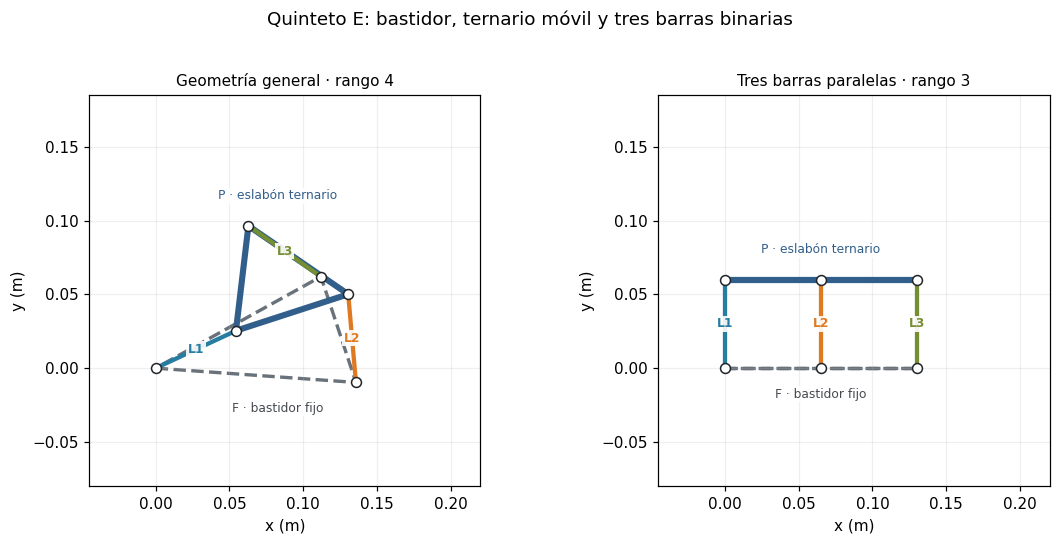

In [8]:
def dibujar_norton(ax, p, b, x, theta, phi, ell, titulo):
    R = rotacion(theta)
    moving = x + (R @ p.T).T
    colores = ["#277da1", "#e07a22", "#758e32"]
    base_closed = np.vstack((b, b[0]))
    ax.plot(base_closed[:, 0], base_closed[:, 1], color="#69727a", lw=2.2,
            linestyle="--", zorder=1)
    moving_closed = np.vstack((moving, moving[0]))
    ax.plot(moving_closed[:, 0], moving_closed[:, 1], color="#315e8a", lw=4,
            solid_capstyle="round", zorder=2)
    for i in range(3):
        end = moving[i]
        ax.plot([b[i, 0], end[0]], [b[i, 1], end[1]], color=colores[i],
                lw=2.8, solid_capstyle="round", zorder=3)
        ax.scatter([b[i, 0], end[0]], [b[i, 1], end[1]], s=42,
                   facecolors="white", edgecolors="#20252a", zorder=5)
        middle = (b[i] + end) / 2
        ax.text(middle[0], middle[1], f"L{i+1}", color=colores[i],
                fontsize=8, weight="bold", ha="center", va="center",
                bbox=dict(facecolor="white", edgecolor="none", alpha=.9, pad=1))
    ax.text(np.mean(b[:, 0]), np.min(b[:, 1]) - .020, "F · bastidor fijo",
            ha="center", fontsize=8, color="#454a50",
            bbox=dict(facecolor="white", edgecolor="none", alpha=.85, pad=1))
    ax.text(np.mean(moving[:, 0]), np.max(moving[:, 1]) + .018, "P · eslabón ternario",
            ha="center", fontsize=8, color="#315e8a",
            bbox=dict(facecolor="white", edgecolor="none", alpha=.85, pad=1))
    ax.set_title(titulo, fontsize=10)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlim(-.045, .220)
    ax.set_ylim(-.080, .185)
    ax.grid(alpha=.2)
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")

fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.8))
dibujar_norton(ax[0], p_general, b_general, x_general, theta_general,
               phi_general, ell, "Geometría general · rango 4")
dibujar_norton(ax[1], p_especial, b_especial, ell*u(np.pi/2), 0.0,
               phi_especial, ell, "Tres barras paralelas · rango 3")
fig.suptitle("Quinteto E: bastidor, ternario móvil y tres barras binarias", y=1.02)
fig.tight_layout()
plt.show()

En la geometría general el jacobiano reducido tiene rango cuatro y el mecanismo queda bloqueado en la configuración mostrada. En la geometría especial se cumple $\mathbf p_i-\mathbf p_1=\mathbf b_i-\mathbf b_1$, con $\theta=0$ y $\phi_1=\phi_2=\phi_3=\pi/2$. El rango baja a tres y aparece una dirección instantánea de movimiento. Además, existe una familia finita de configuraciones:

$$
\phi_1=\phi_2=\phi_3=\varphi,\qquad
\theta=0,\qquad
\mathbf x=\ell\mathbf u(\varphi).
$$

Para todo $\varphi$, cada barra conserva su longitud y la placa ternaria mantiene su orientación mientras se traslada. La animación recorre parte de esa familia. El grafo $K_{2,3}$ y sus dos ciclos no cambian; la geometría asignada a los vértices y las articulaciones cambia el rango de las ecuaciones.

### Animación de la movilidad especial

La configuración especial tiene una familia finita de movimiento: las tres barras binarias giran en paralelo mientras el eslabón ternario conserva su orientación. El encuadre permanece fijo.

Animación guardada: animaciones\norton_quinteto_e.gif



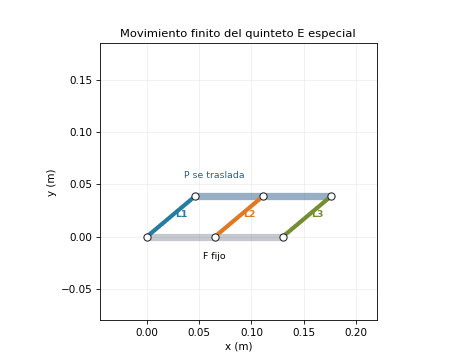

In [9]:
fig, ax = plt.subplots(figsize=(6.2, 4.8))
phi_motion = np.linspace(np.deg2rad(40), np.deg2rad(140), 44)

def actualizar_norton(i):
    ax.clear()
    phi = phi_motion[i]
    x = ell * u(phi)
    moving = x + p_especial
    ax.plot(p_especial[:, 0], p_especial[:, 1], color="#59636e", lw=7,
            alpha=.35, solid_capstyle="round")
    ax.plot(moving[:, 0], moving[:, 1], color="#315e8a", lw=7,
            alpha=.5, solid_capstyle="round")
    for j, color in enumerate(("#277da1", "#e07a22", "#758e32")):
        ax.plot([b_especial[j, 0], moving[j, 0]],
                [b_especial[j, 1], moving[j, 1]], color=color, lw=4)
        ax.scatter([b_especial[j, 0], moving[j, 0]],
                   [b_especial[j, 1], moving[j, 1]], s=48,
                   facecolors="white", edgecolors="#20252a", zorder=4)
        ax.text((b_especial[j, 0] + moving[j, 0]) / 2 + .004,
                (b_especial[j, 1] + moving[j, 1]) / 2, f"L{j+1}",
                fontsize=9, color=color, weight="bold")
    ax.text(.065, -.021, "F fijo", ha="center", fontsize=9)
    ax.text(.065, moving[1, 1] + .018, "P se traslada", ha="center",
            fontsize=9, color="#315e8a")
    ax.set_xlim(-.045, .220)
    ax.set_ylim(-.080, .185)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title("Movimiento finito del quinteto E especial")
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")
    ax.grid(alpha=.2)

anim_norton = FuncAnimation(fig, actualizar_norton, frames=len(phi_motion),
                            interval=100, blit=False, cache_frame_data=False)
gif_norton = PROJECT / "animaciones" / "norton_quinteto_e.gif"
anim_norton.save(gif_norton, writer=PillowWriter(fps=10), dpi=75)
plt.close(fig)
gif_data = base64.b64encode(gif_norton.read_bytes()).decode("ascii")
display(HTML(f'<img alt="Movimiento finito del quinteto E especial" src="data:image/gif;base64,{gif_data}" width="620">'))
print("Animación guardada:", gif_norton.relative_to(PROJECT))

n=5, ε=6, rango de ciclos ε−n+1=2


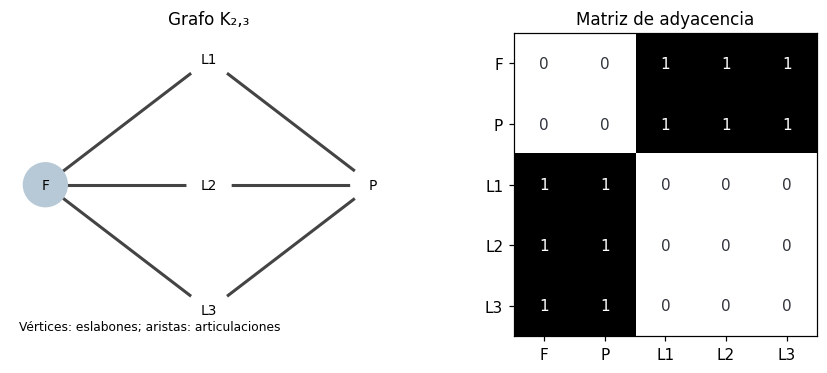

,F,P,L1,L2,L3
F,0,0,1,1,1
P,0,0,1,1,1
L1,1,1,0,0,0
L2,1,1,0,0,0
L3,1,1,0,0,0


In [10]:
norton_vertices = ["F", "P", "L1", "L2", "L3"]
norton_edges = [(body, link) for body in ("F", "P") for link in ("L1", "L2", "L3")]
GN = nx.Graph()
GN.add_nodes_from(norton_vertices)
GN.add_edges_from(norton_edges)
AdjN = nx.to_numpy_array(GN, nodelist=norton_vertices, dtype=int)
posN = {"F": (-1, 0), "P": (1, 0), "L1": (0, 1), "L2": (0, 0), "L3": (0, -1)}
fig, ax = plt.subplots(1, 2, figsize=(8.5, 3.5), gridspec_kw={"width_ratios": [1, 1.25]})
nx.draw_networkx(GN, posN, ax=ax[0],
                 node_color=["#b7c9d6" if v == "F" else "white" for v in norton_vertices],
                 node_size=820, edge_color="#444", width=2, font_size=9)
ax[0].set_title("Grafo K₂,₃")
ax[0].text(.02, .02, "Vértices: eslabones; aristas: articulaciones",
           transform=ax[0].transAxes, fontsize=8)
ax[0].axis("off")
ax[1].imshow(AdjN, cmap="Greys", vmin=0, vmax=1)
ax[1].set_xticks(range(5), norton_vertices)
ax[1].set_yticks(range(5), norton_vertices)
ax[1].set_title("Matriz de adyacencia")
for i in range(5):
    for j in range(5):
        ax[1].text(j, i, str(AdjN[i, j]), ha="center", va="center",
                    color="white" if AdjN[i, j] else "#30343b")
fig.tight_layout()
plt.show()
rango_norton = GN.number_of_edges() - GN.number_of_nodes() + 1
print(f"n={GN.number_of_nodes()}, ε={GN.number_of_edges()}, rango de ciclos ε−n+1={rango_norton}")
display(pd.DataFrame(AdjN, index=norton_vertices, columns=norton_vertices))

## 5. Aplicación al submecanismo planar del EEZYbotARM

El EEZYbotARM es un brazo educativo de diseño abierto. Para este análisis se fija la base giratoria y la orientación de la pinza, y se estudia un submecanismo planar formado por ocho eslabones móviles, dos coordenadas articulares independientes y once articulaciones revolutas. El ejemplo conecta la definición matemática del grafo con un mecanismo construido, sus ciclos geométricos y sus balances dinámicos.

Las siguientes imágenes reúnen una fotografía y esquemas del material de taller de Luis Alejandro Rodríguez Arenas [8]. La fotografía muestra la identificación física de los eslabones. Los croquis coloreados muestran cómo se reconocieron ciclos y cómo se organizaron los vectores de cierre. La notación del análisis se introduce de nuevo a continuación para que el procedimiento pueda seguirse sin conocer el material de origen.


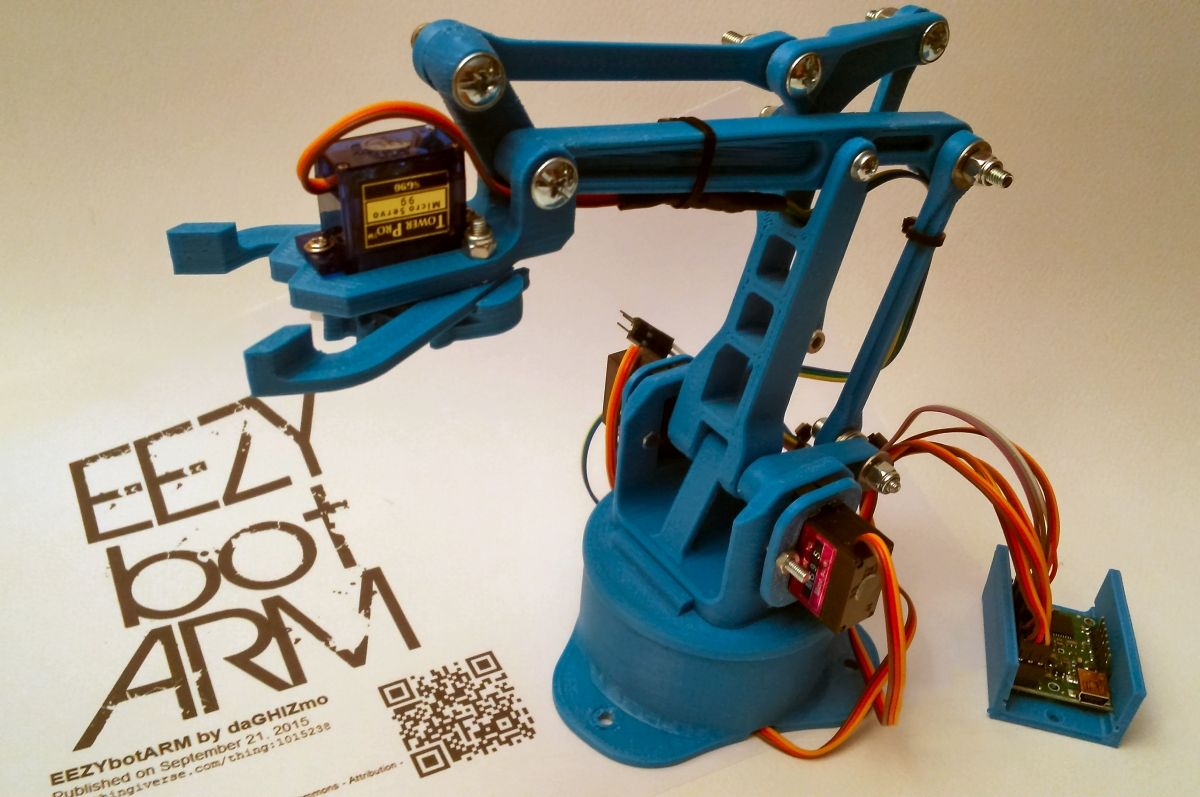
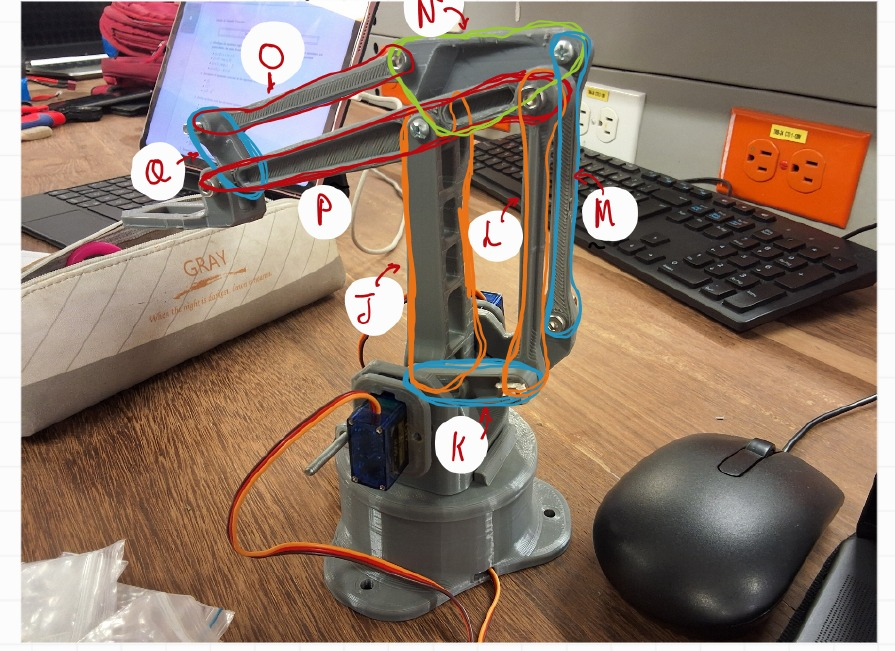
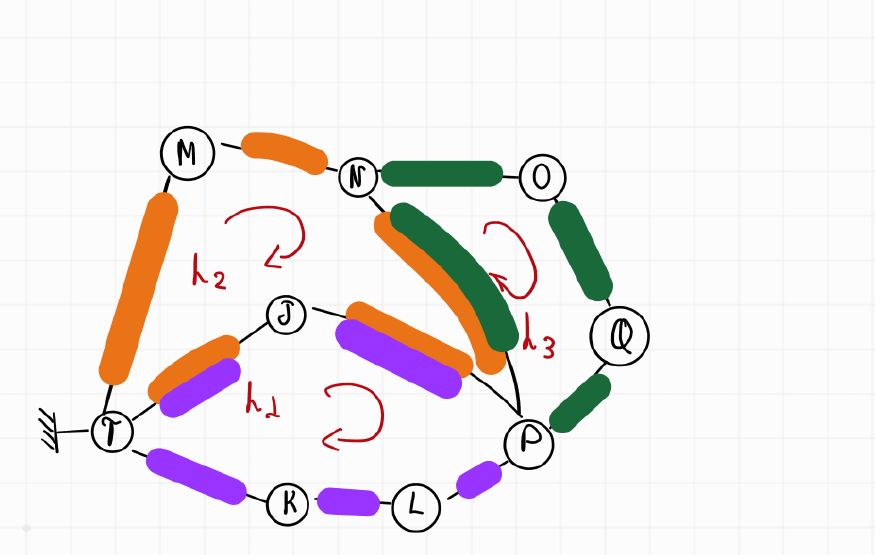
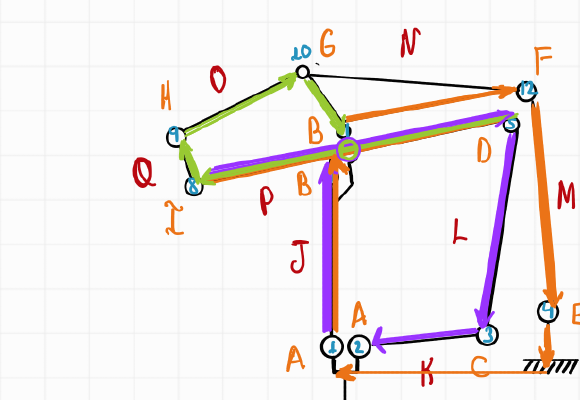

In [11]:
def imagen_local(nombre, leyenda, ancho):
    archivo = PROJECT / "figuras" / nombre
    if not archivo.exists():
        return f'<figure><figcaption>No se encontró {nombre}</figcaption></figure>'
    extension = archivo.suffix.lower()
    mime = "image/jpeg" if extension in (".jpg", ".jpeg") else "image/png"
    datos = base64.b64encode(archivo.read_bytes()).decode("ascii")
    return (
        '<figure style="margin:12px;text-align:center">'
        f'<img src="data:{mime};base64,{datos}" alt="{leyenda}" '
        f'style="max-width:100%;width:{ancho}px;height:auto">'
        f'<figcaption style="font-size:0.95em;margin-top:6px">{leyenda}</figcaption>'
        '</figure>'
    )

gallery = (
    '<div style="display:grid;grid-template-columns:repeat(2,minmax(0,1fr));'
    'gap:12px;align-items:start">'
    + imagen_local("eezybotarm_instructables.jpg",
                   "EEZYbotARM de diseño abierto, imagen contextual del proyecto.", 620)
    + imagen_local("eezybotarm_taller_foto.jpg",
                   "Prototipo fotografiado y rotulado durante el trabajo de taller.", 620)
    + imagen_local("eezybotarm_taller_grafo.png",
                   "Croquis del grafo mecánico y de sus ciclos.", 520)
    + imagen_local("eezybotarm_taller_ciclos.png",
                   "Esquema de recorridos vectoriales sobre el mecanismo.", 520)
    + '</div>'
)
display(HTML(gallery))

### Grafo, matriz y ciclos del mecanismo

Se designa el bastidor por $T$ y los eslabones móviles por $J,K,L,M,N,O,P,Q$. Las once aristas son $TJ,JP,JN,TK,KL,LP,TM,MN,NO,OQ,QP$. El grafo es conexo, tiene $n=9$ vértices y $\epsilon=11$ aristas. Por tanto, el rango de ciclos es $\epsilon-n+1=3$.

Un árbol recubridor posible contiene ocho aristas. Las tres restantes, $LP,MN,QP$, son cuerdas. Al agregar cada cuerda al árbol se obtiene uno de los tres ciclos fundamentales. El siguiente código construye la matriz y destaca el árbol y las cuerdas sobre el mismo grafo.

Vértices n=9 | articulaciones ε=11 | componentes=1
Rango de ciclos, ε−n+1 = 3
Ciclos obtenidos a partir de las cuerdas del árbol:
 • T-J-P-L-K-T T → J → P → L → K → T
 • T-J-N-M-T T → J → N → M → T
 • J-P-Q-O-N-J J → P → Q → O → N → J


,T,J,K,L,M,N,O,P,Q
T,0,1,1,0,1,0,0,0,0
J,1,0,0,0,0,1,0,1,0
K,1,0,0,1,0,0,0,0,0
L,0,0,1,0,0,0,0,1,0
M,1,0,0,0,0,1,0,0,0
N,0,1,0,0,1,0,1,0,0
O,0,0,0,0,0,1,0,0,1
P,0,1,0,1,0,0,0,0,1
Q,0,0,0,0,0,0,1,1,0


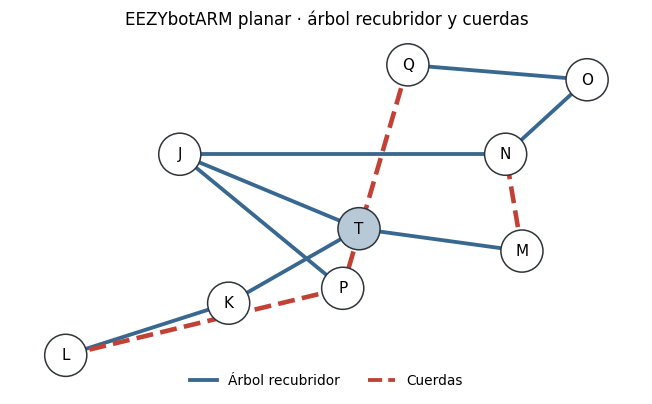

In [12]:
V = list(mech.VERTICES)
E = list(mech.EDGES)
G = nx.Graph()
G.add_nodes_from(V)
G.add_edges_from(E)
Adj_M = np.asarray(mech.adjacency_matrix(), dtype=int)
print(f"Vértices n={len(V)} | articulaciones ε={len(E)} | componentes={nx.number_connected_components(G)}")
print("Rango de ciclos, ε−n+1 =", G.number_of_edges() - G.number_of_nodes() + 1)
print("Ciclos obtenidos a partir de las cuerdas del árbol:")
for nombre, ciclo in zip(mech.CYCLE_NAMES, mech.CYCLES):
    print(" •", nombre, " → ".join(ciclo))
display(pd.DataFrame(Adj_M, index=V, columns=V))

pos = {"T": (0, 0), "J": (-1.1, 1.0), "K": (-.8, -1.0), "L": (-1.8, -1.7),
       "M": (1.0, -.3), "N": (.9, 1.0), "O": (1.4, 2.0), "Q": (.3, 2.2), "P": (-.1, -.8)}
tree_edges = list(mech.TREE_EDGES)
chords = list(mech.CHORDS)
fig, ax = plt.subplots(figsize=(7.4, 4.5))
nx.draw_networkx_nodes(G, pos, ax=ax,
                       node_color=["#b7c9d6" if v == "T" else "white" for v in V],
                       edgecolors="#30343b", node_size=760)
nx.draw_networkx_labels(G, pos, ax=ax, font_size=10)
nx.draw_networkx_edges(G, pos, edgelist=tree_edges, ax=ax,
                       edge_color="#386890", width=2.5)
nx.draw_networkx_edges(G, pos, edgelist=chords, ax=ax,
                       edge_color="#c24135", style="dashed", width=3)
ax.set_title("EEZYbotARM planar · árbol recubridor y cuerdas")
ax.axis("off")
from matplotlib.lines import Line2D
handles = [Line2D([0], [0], color="#386890", lw=2.5, label="Árbol recubridor"),
           Line2D([0], [0], color="#c24135", lw=2.5, ls="--", label="Cuerdas")]
ax.legend(handles=handles, loc="lower center", bbox_to_anchor=(.5, -.04),
          ncol=2, frameon=False, fontsize=9)
fig.subplots_adjust(bottom=.17)
plt.show()

La misma cuenta puede leerse en la matriz de incidencia orientada $B$. Cada columna contiene un $-1$ en el vértice de salida y un $+1$ en el vértice de llegada. Como el grafo es conexo, $\operatorname{rank}(B)=n-1$. Por el teorema rango-nulidad, la nulidad de $B$ es $\epsilon-n+1=3$, y los vectores de incidencia orientados de los tres ciclos fundamentales forman una base del núcleo.

In [13]:
incidence = np.zeros((len(V), len(E)), dtype=int)
for col, (a, b) in enumerate(E):
    incidence[V.index(a), col] = -1
    incidence[V.index(b), col] = 1
rank_B = np.linalg.matrix_rank(incidence)
print(f"Matriz de incidencia B: {incidence.shape[0]} × {incidence.shape[1]}")
print(f"rango(B)={rank_B}; nulidad(B)=ε−n+1={incidence.shape[1]-rank_B}")
print("Nulidad calculada:", len(E) - len(V) + 1)

Matriz de incidencia B: 9 × 11
rango(B)=8; nulidad(B)=ε−n+1=3
Nulidad calculada: 3


### De un ciclo del grafo a un cierre vectorial

Considérese un ciclo alternante de eslabones y articulaciones

$$
C=(v_1,e_1,v_2,e_2,\ldots,v_k,e_k,v_1),
$$

donde $e_i$ une los eslabones $v_i$ y $v_{i+1}$, con índices cíclicos. Sea $\mathbf z_i$ la posición, en el plano, del centro de la articulación $e_i$. Sobre el eslabón $v_i$, sean $\rho(v_i,e_{i-1})$ y $\rho(v_i,e_i)$ las coordenadas locales de los dos pivotes consecutivos. La rotación del eslabón transforma el vector entre esos pivotes al marco global:

$$
\mathbf r_i(q)=R(\theta_i)\bigl(\rho(v_i,e_i)-\rho(v_i,e_{i-1})\bigr).
$$

**Demostración.** En una articulación revoluta ideal, el centro del pivote tiene la misma posición cuando se describe desde cualquiera de los dos eslabones incidentes. Por ello, al recorrer $v_i$ desde $e_{i-1}$ hasta $e_i$, se cumple $\mathbf z_i-\mathbf z_{i-1}=\mathbf r_i(q)$. Al sumar las igualdades alrededor del ciclo, los puntos de articulación se cancelan en forma telescópica:

$$
\sum_{i=1}^{k}\mathbf r_i(q)
=\sum_{i=1}^{k}(\mathbf z_i-\mathbf z_{i-1})
=\mathbf 0.
$$

Así, cada ciclo fundamental del grafo proporciona un cierre vectorial. En un mecanismo planar cada cierre tiene dos componentes escalares. Los ciclos de la base son independientes como ciclos de aristas; sus ecuaciones geométricas se obtienen al sustituir las dimensiones y orientaciones locales de los eslabones.

In [14]:
q0 = np.asarray(mech.default_configuration()["q_rad"], dtype=float)
phi_graph, J_graph = mech.closure_jacobian(q0)
phi_explicit = mech.legacy_closures(q0)
print("Residuo de los cierres generados desde ciclos:", f"{np.linalg.norm(phi_graph):.3e}", "m")
print("Diferencia respecto a cierres explícitos:", f"{np.max(np.abs(phi_graph-phi_explicit)):.3e}", "m")
print("Ecuaciones escalares de cierre:", len(phi_graph))
print("La comparación confirma que la construcción desde el grafo reproduce los tres loops del modelo.")

Residuo de los cierres generados desde ciclos: 6.894e-12 m
Diferencia respecto a cierres explícitos: 3.469e-18 m
Ecuaciones escalares de cierre: 6
La comparación confirma que la construcción desde el grafo reproduce los tres loops del modelo.


Las tres expresiones explícitas que se comparan son

$$
\begin{aligned}
\Phi_1&=\mathbf r_{AB}+\mathbf r_{BD}-\mathbf r_{CD}-\mathbf r_{AC}=\mathbf 0,\\
\Phi_2&=\mathbf r_{AB}+\mathbf r_{BF}-\mathbf r_{EF}-\mathbf r_{AE}=\mathbf 0,\\
\Phi_3&=-\mathbf r_{IB}+\mathbf r_{IH}+\mathbf r_{HG}-\mathbf r_{BG}=\mathbf 0.
\end{aligned}
$$

Cada vector $\mathbf r$ une dos articulaciones del mismo eslabón. Su dirección depende de la orientación del eslabón y su magnitud de la geometría local. El ciclo determina qué segmentos se recorren y con qué signo; las dimensiones transforman el recorrido en ecuaciones concretas.

### Cinemática directa, velocidades y aceleraciones

El vector de orientación contiene ocho ángulos, uno por eslabón móvil. Solo $\theta_1$ y $\theta_2$ son coordenadas independientes en este submecanismo. La cinemática directa fija esos dos ángulos de entrada y resuelve los otros seis para satisfacer los seis componentes escalares de cierre. La rutina adapta el cálculo del modelo mecánico previo: minimiza el residuo de cierre con BFGS y utiliza la solución anterior como estimación inicial para continuar sobre la misma rama.

Si $\boldsymbol\Phi(q)=\mathbf 0$ representa los cierres, su derivada temporal impone la compatibilidad de velocidades:

$$
J(q)\dot q=\mathbf 0,\qquad
J(q)=\frac{\partial\boldsymbol\Phi}{\partial q}.
$$

Al derivar de nuevo se obtiene la compatibilidad de aceleraciones:

$$
J(q)\ddot q+\dot J(q,\dot q)\dot q=\mathbf 0.
$$

El término $\dot J\dot q$ se calcula numéricamente como $\gamma(q,\dot q)$. Estas relaciones reconstruyen las velocidades y aceleraciones de los seis eslabones pasivos a partir de las dos entradas.

In [15]:
active_deg = np.array([90.0, 0.0])
q = mech.solve_configuration(np.deg2rad(active_deg))
qd = mech.compatible_velocity(q, np.deg2rad([20.0, 35.0]))
qdd = mech.compatible_acceleration(q, qd, np.deg2rad([5.0, -8.0]))
phi, J = mech.closure_jacobian(q)
gamma = mech.closure_gamma(q, qd)
print("Ángulos de entrada impuestos (grados):", active_deg)
print("Ángulos reconstruidos del mecanismo (grados):", np.round(np.rad2deg(q), 3))
print("||Φ(q)|| =", f"{np.linalg.norm(phi):.3e}")
print("||J q̇|| =", f"{np.linalg.norm(J @ qd):.3e}")
print("||J q̈ + γ|| =", f"{np.linalg.norm(J @ qdd + gamma):.3e}")

Ángulos de entrada impuestos (grados): [90.  0.]
Ángulos reconstruidos del mecanismo (grados): [ 90.      0.     90.     90.001  25.515   0.      0.    120.515]
||Φ(q)|| = 6.894e-12
||J q̇|| = 3.469e-18
||J q̈ + γ|| = 9.699e-19


### Reproducción de las dos rutinas cinemáticas

Las animaciones recuperan dos rutinas de entrada del modelo. En cada cuadro se resuelven los seis ángulos pasivos a partir de $\theta_1(t)$ y $\theta_2(t)$. Los pivotes de base permanecen en un marco de referencia fijo. Todas las figuras usan límites de eje constantes en todos sus cuadros y dejan margen alrededor del mecanismo completo.

Rutina 1: residuo máximo de cierre = 2.425e-11 m
Rutina 2: residuo máximo de cierre = 3.829e-11 m
Animación guardada: animaciones\rutina_cinematica_1.gif (414 KiB)



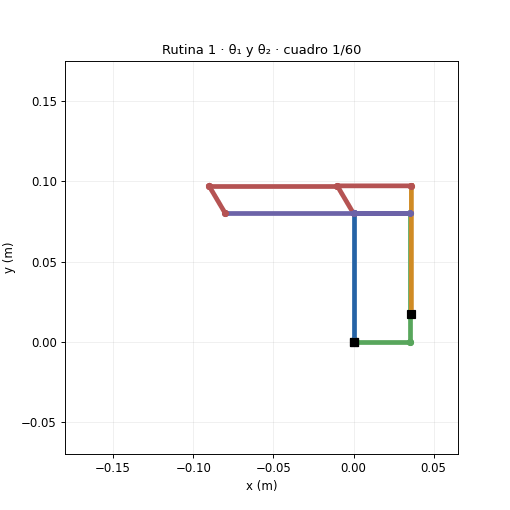

In [16]:
def dibujar_mecanismo(ax, frame):
    joints = frame["joint_positions"]
    colores = {"J": "#2563a6", "K": "#58a65c", "L": "#58a65c", "M": "#d08b24",
               "N": "#b55353", "O": "#b55353", "P": "#6c63a8", "Q": "#b55353"}
    for body, path in mech.body_paths().items():
        xy = np.array([joints[name] for name in path])
        ax.plot(xy[:, 0], xy[:, 1], "o-", lw=4, ms=5, color=colores[body])
    for key in ("TJ", "TK", "TM"):
        xy = np.asarray(joints[key])
        ax.plot(xy[0], xy[1], "ks", ms=7)
    ax.set_xlim(-0.18, 0.065)
    ax.set_ylim(-0.07, 0.175)
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=.2)
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")

def mostrar_animacion(frames, titulo, nombre, fps=15):
    if len(frames) > 60:
        indices = np.linspace(0, len(frames) - 1, 60).round().astype(int)
        frames = [frames[i] for i in indices]
    fig, ax = plt.subplots(figsize=(6.0, 6.0))
    def update(i):
        ax.clear()
        dibujar_mecanismo(ax, frames[i])
        ax.set_title(f"{titulo} · cuadro {i+1}/{len(frames)}")
    anim = FuncAnimation(fig, update, frames=len(frames),
                         interval=1000/fps, blit=False, cache_frame_data=False)
    output_dir = PROJECT / "animaciones"
    output_dir.mkdir(exist_ok=True)
    output_path = output_dir / f"{nombre}.gif"
    anim.save(output_path, writer=PillowWriter(fps=fps), dpi=85)
    plt.close(fig)
    encoded = base64.b64encode(output_path.read_bytes()).decode("ascii")
    display(HTML(f'<img alt="{titulo}" src="data:image/gif;base64,{encoded}" width="570">'))
    print(f"Animación guardada: {output_path.relative_to(PROJECT)} ({output_path.stat().st_size/1024:.0f} KiB)")

rutina1 = mech.simulate_kinematic_routine("animation1", samples=120)
rutina2 = mech.simulate_kinematic_routine("animation2", samples=120)
print("Rutina 1: residuo máximo de cierre =", f"{rutina1['max_closure_norm']:.3e}", "m")
print("Rutina 2: residuo máximo de cierre =", f"{rutina2['max_closure_norm']:.3e}", "m")
mostrar_animacion(rutina1["frames"], "Rutina 1 · θ₁ y θ₂", "rutina_cinematica_1")

Animación guardada: animaciones\rutina_cinematica_2.gif (284 KiB)



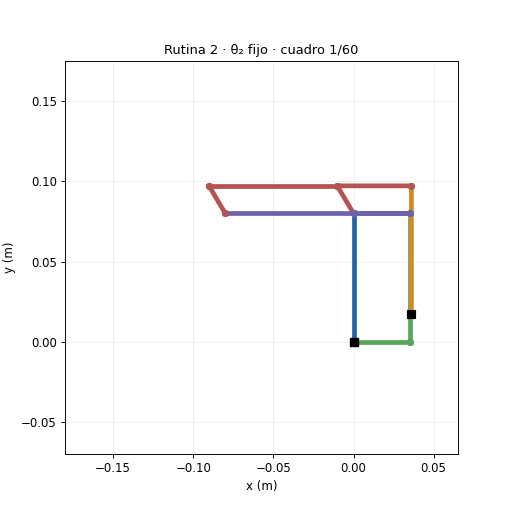

In [17]:
mostrar_animacion(rutina2["frames"], "Rutina 2 · θ₂ fijo", "rutina_cinematica_2")

## 6. De los ciclos a la dinámica de Newton y Euler

Los ciclos organizan los cierres geométricos del mecanismo. Al resolverlos se obtienen posiciones compatibles; al derivarlos se obtienen velocidades y aceleraciones compatibles. Esas magnitudes cinemáticas aparecen en los balances dinámicos de cada eslabón. Además, cada arista del grafo identifica una articulación donde actúan fuerzas de reacción entre dos cuerpos.

Para cada eslabón móvil se escriben dos componentes de la segunda ley de Newton para el centro de masa y una ecuación de Euler para la rotación. Con ocho eslabones móviles resultan 24 ecuaciones escalares. Las once articulaciones aportan 22 componentes de fuerza de reacción y los dos actuadores aportan dos torques desconocidos. En dinámica inversa, conocida la trayectoria, se resuelve ese sistema lineal para obtener las fuerzas y los torques que la producen.

En dinámica directa, conocidos los torques y el estado actual, los balances de Newton y Euler se acoplan con las seis condiciones de aceleración derivadas de los tres cierres. El sistema resultante determina las ocho aceleraciones angulares y las 22 reacciones articulares. Así, los ciclos aportan las restricciones geométricas y cinemáticas que conectan la estructura del grafo con la dinámica de los eslabones.

### Dinámica inversa: torques para una rutina prescrita

Se prescribe la primera rutina cinemática:

$$
\theta_1(t)=90^\circ+35^\circ\bigl(1-\cos(t/2)\bigr),\qquad
\theta_2(t)=45^\circ\bigl(1-\cos t\bigr).
$$

Sus derivadas se expresan en radianes por segundo y radianes por segundo cuadrado. En cada muestra, los cierres reconstruyen las coordenadas pasivas y sus derivadas compatibles; luego los balances de Newton y Euler calculan los torques requeridos.

Residuo máximo de Newton y Euler: 1.110e-16


,t (s),τ₁ (N·m),τ₂ (N·m),residuo del sistema
0,0.000000,0.000028,-0.006577,0.0
7,1.466077,-0.003957,-0.005052,0.0
15,3.141593,-0.014432,-0.000048,0.0
23,4.817109,-0.022125,-0.005051,0.0
30,6.283185,-0.023692,-0.006586,0.0


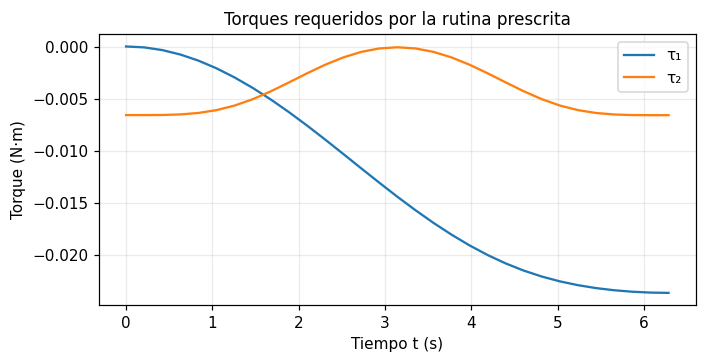

In [18]:
tiempos = np.linspace(0.0, 2*np.pi, 31)
filas = []
for t in tiempos:
    theta1 = np.deg2rad(90 + 35 * (1 - np.cos(t/2)))
    theta2 = np.deg2rad(45 * (1 - np.cos(t)))
    vel_activa = np.deg2rad([35/2 * np.sin(t/2), 45 * np.sin(t)])
    acel_activa = np.deg2rad([35/4 * np.cos(t/2), 45 * np.cos(t)])
    q = mech.solve_configuration((theta1, theta2))
    qd = mech.compatible_velocity(q, vel_activa)
    qdd = mech.compatible_acceleration(q, qd, acel_activa)
    resultado = mech.inverse_dynamics(q, qd, qdd)
    filas.append([t, *resultado["torques"], resultado["newton_euler_residual"]])
dinamica_inversa = pd.DataFrame(filas, columns=["t (s)", "τ₁ (N·m)", "τ₂ (N·m)", "residuo del sistema"])
display(dinamica_inversa.iloc[[0, 7, 15, 23, 30]].round(7))
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(dinamica_inversa["t (s)"], dinamica_inversa["τ₁ (N·m)"], label="τ₁")
ax.plot(dinamica_inversa["t (s)"], dinamica_inversa["τ₂ (N·m)"], label="τ₂")
ax.set_xlabel("Tiempo t (s)")
ax.set_ylabel("Torque (N·m)")
ax.set_title("Torques requeridos por la rutina prescrita")
ax.grid(alpha=.25)
ax.legend()
plt.show()
print("Residuo máximo de Newton y Euler:", f"{dinamica_inversa['residuo del sistema'].max():.3e}")

### Dinámica directa: torques aplicados y caída sin torque

La simulación integra únicamente $\theta_1$ y $\theta_2$, las dos coordenadas independientes. En cada evaluación temporal, los ciclos resuelven las otras seis orientaciones y sus velocidades. Los balances de Newton y Euler determinan las aceleraciones compatibles con los torques aplicados y la gravedad.

Se comparan dos casos desde la misma posición inicial y con velocidades iniciales nulas. El primero aplica torques a los dos actuadores. En el segundo, $\tau_1=\tau_2=0$ y la gravedad permanece activa, de modo que se observa la caída del mecanismo sin actuación motora. Las dos animaciones muestran el mecanismo completo dentro de un marco fijo.

Torque aplicado: τ₁=0.0005 N·m, τ₂=−0.0005 N·m
Residuo máximo de cierre: 8.555e-12 m
Sin torque: τ₁=τ₂=0; gravedad activa
Residuo máximo de cierre: 2.097e-11 m
Animación guardada: animaciones\dinamica_directa_torques.gif (165 KiB)



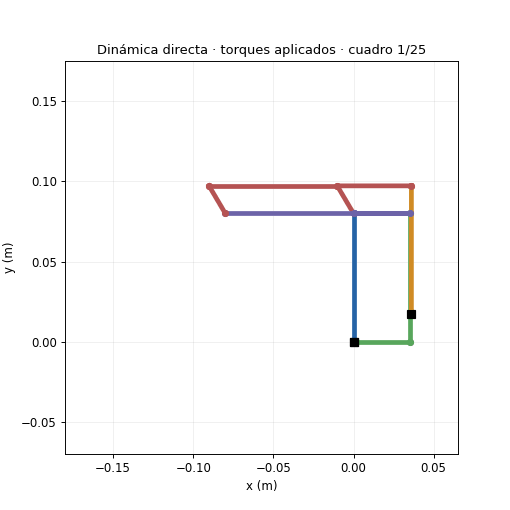

In [19]:
caso_torque = mech.simulate_forward((90, 0), (0, 0), (0.0005, -0.0005), duration_s=0.15, samples=25)
caso_sin_torque = mech.simulate_forward((90, 0), (0, 0), (0.0, 0.0), duration_s=0.15, samples=25)
print("Torque aplicado: τ₁=0.0005 N·m, τ₂=−0.0005 N·m")
print("Residuo máximo de cierre:", f"{caso_torque['max_closure_norm']:.3e}", "m")
print("Sin torque: τ₁=τ₂=0; gravedad activa")
print("Residuo máximo de cierre:", f"{caso_sin_torque['max_closure_norm']:.3e}", "m")
mostrar_animacion(caso_torque["frames"], "Dinámica directa · torques aplicados", "dinamica_directa_torques", fps=12)

Animación guardada: animaciones\dinamica_directa_torques_cero.gif (169 KiB)
Ángulos finales con torques: [103.14  60.86] grados
Ángulos finales sin torques: [102.73  66.02] grados



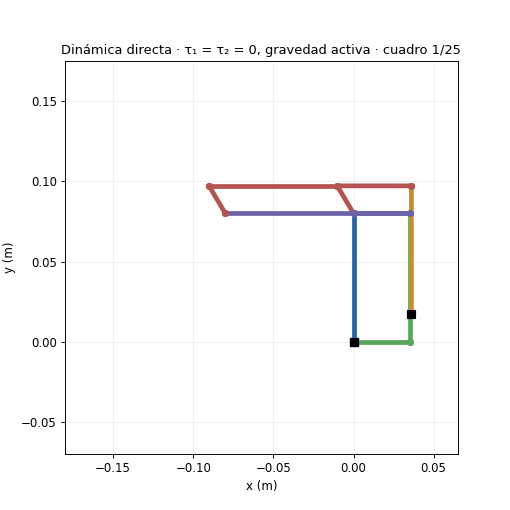

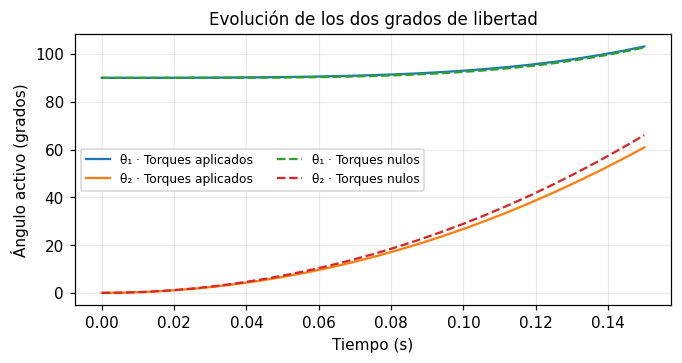

In [20]:
mostrar_animacion(caso_sin_torque["frames"], "Dinámica directa · τ₁ = τ₂ = 0, gravedad activa",
                  "dinamica_directa_torques_cero", fps=12)
fig, ax = plt.subplots(figsize=(7, 3.2))
for caso, etiqueta, estilo in ((caso_torque, "Torques aplicados", "-"),
                               (caso_sin_torque, "Torques nulos", "--")):
    t = [f["time"] for f in caso["frames"]]
    q1 = [f["q_deg"][0] for f in caso["frames"]]
    q2 = [f["q_deg"][1] for f in caso["frames"]]
    ax.plot(t, q1, linestyle=estilo, label=f"θ₁ · {etiqueta}")
    ax.plot(t, q2, linestyle=estilo, label=f"θ₂ · {etiqueta}")
ax.set_xlabel("Tiempo (s)")
ax.set_ylabel("Ángulo activo (grados)")
ax.set_title("Evolución de los dos grados de libertad")
ax.grid(alpha=.25)
ax.legend(ncol=2, fontsize=8)
plt.show()
print("Ángulos finales con torques:", np.round(caso_torque["frames"][-1]["q_deg"][:2], 2), "grados")
print("Ángulos finales sin torques:", np.round(caso_sin_torque["frames"][-1]["q_deg"][:2], 2), "grados")

## 7. Alcance y conclusiones

La representación por grafos separa conectividad y geometría. La matriz de adyacencia registra qué eslabones están unidos; un árbol recubridor y sus cuerdas producen una base de ciclos; y las posiciones locales de los pivotes convierten cada ciclo en un cierre vectorial. El quinteto E de Norton permite seguir este paso desde el grafo hasta las ecuaciones y comparar dos geometrías con la misma conectividad.

En el submecanismo planar del EEZYbotARM, tres ciclos producen seis cierres escalares. Estos cierres reconstruyen las seis orientaciones pasivas, permiten calcular velocidades y aceleraciones compatibles y se acoplan a los balances de Newton y Euler. Las demostraciones incluyen el movimiento de cuatro barras, cambios de numeración y conectividad, el movimiento finito del quinteto E, dos rutinas cinemáticas, dinámica inversa y dinámica directa con torques nulos y aplicados.

El modelo idealiza las articulaciones como revolutas sin holgura ni fricción y utiliza las propiedades geométricas e inerciales del modelo mecánico. Las simulaciones exponen el procedimiento matemático y no sustituyen una validación experimental del prototipo.

## Referencias

1. Martínez, M. (2026). *Representación de grafos con matrices y listas de adyacencias*. Diapositivas de MATE-1018, semana 2.
2. Martínez, M. (2026). *Árboles, bosques y ciclos*. Diapositivas de MATE-1018, semana 9.
3. Norton, R. L. (1999). *Design of Machinery*, 2.ª ed., capítulo 2, sección 2.7. McGraw-Hill.
4. Kocay, W. y Kreher, D. L. (2005). *Graphs, Algorithms, and Optimization*. Chapman and Hall/CRC.
5. Parrish, B. E., McCarthy, J. M. y Eppstein, D. (2015). “Automated generation of linkage loop equations for planar one degree of freedom linkages demonstrated up to 8 bar”. *Journal of Mechanisms and Robotics*, 7(1), 011006. [doi:10.1115/1.4029306](https://doi.org/10.1115/1.4029306).
6. theGHIZmo (2015). [EEZYbotARM](https://www.instructables.com/EEZYbotARM/). Diseño abierto e imagen contextual.
7. Rodríguez Arenas, L. A. (2026). Modelo cinemático y dinámico del EEZYbotARM. Material de referencia no publicado; el repositorio original del taller no se duplica en esta entrega.

8. Rodríguez Arenas, L. A. (2026). Material gráfico de análisis del EEZYbotARM. Documento personal no publicado.

La implementación utiliza Python, NumPy, SciPy, NetworkX, Matplotlib y pandas.